This notebook allows to experiment and compute the faithfulness metric $\mathcal{{F}}_{{syn}}$ and generate and visualize explanations on VLM model.

In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))

import transformers
from packaging.version import Version
if Version(transformers.__version__) > Version("5.10"):
    import src.utils.lxt_shim

In [ ]:
from typing import Any, Sequence


import numpy as np
from torch import Tensor
import yaml


# --- ABSTRACTED FACTORIES & UTILS ---
from src.datasets.factory import get_dataloader 
from src.models.factory import load_vlm

# --- EXPLAINERS & METRICS ---
from src.metrics import FaithfulnessMetric


### Load model

Specify which VLM model you want to use

Available architectures
- InternVL 3.5 2B : `internvl_2b`
- InternVL 3.5 14B : `internvl_14b`
- LlaVa 1.5 7B : `llava_7b`
- LlaVa 1.5 13B: `llava_13b`
- QwenVL 2.5 3B: `qwen2_5_vl_3b`
- QwenVL 2.5 7B: `qwen2_5_vl_7b`
- Qwen 3-5 2B: `qwen3_5_2b`
- Qwen 3-5 27B: `qwen3_5_27b`


In [ ]:

def load_yaml(file_path):
    with open(file_path, encoding="utf-8") as f:
        return yaml.safe_load(f)

model_name = "internvl_2b"
gpu_id = 0


model_config = f"../configs/models/{model_name}.yaml"
model_config = load_yaml(model_config)




In [ ]:
model_wrapper = load_vlm(
    model_config=model_config,
    attn_implementation="eager", 
    gpu_node=gpu_id,
    output_attentions=True
)


### Load Dataset

Specify which dataset you want to use.

Available datasets:
- RePOPE: `repope`
- MMStar: `mmstar`
- CVBench: `cvbench`
- COCO: `coco`

When loading the datasets `coco` and `repope`, you will need to download the `coco` datasets (see `README.md`).
For `mmstar` and `cvbench`, you can just follow the rest of the notebook, as they are available on HuggingFace.

In [ ]:
dataset_name = "repope_oracle"

if dataset_name in ['repope', 'repope_oracle']:
    dataset_config = {
    "name": dataset_name,
    "data_path": "../datasets/repope",
    "pope_json_path": "../datasets/repope/repope_annotations",
    "pope_type": "all",
    "coco_split": "val2014",
    "batch_size": 1,
    }
    

else:

    dataset_config = f"../configs/datasets/{dataset_name}.yaml"
    dataset_config = load_yaml(dataset_config)


In [8]:
dl = get_dataloader(dataset_config)

[*] Loading Dataset: repope_oracle
loading annotations into memory...
Done (t=3.72s)
creating index...
index created!
[*] Scanning 3 POPE json files...
[*] Built 'all' split. Total unique questions: 1203


### Get one sample

We will pick one sample for the demo.
Change the `idx` variable to change the sample.

In [ ]:
idx = 36


In [ ]:

sample = dl.dataset[idx]
category = sample.get("category", None)


    
img = sample.get("image", None)

question = sample.get("question", None)
if dataset_name in ["repope", "repope_oracle"]:
    text = question
else:
    if model_config["name"] == "llava":
        constraint = "\nAnswer"
    else:
        constraint = "\nAnswer directly with only the letter inside parentheses, and nothing else."
    text = constraint + question
label = sample.get("label", None)

keyword=sample.get("object_name", None)
oracle_mask_2d=sample.get("pixel_oracle_mask", None)
mismatched_mask_2d=sample.get("distractor_mask", None)


In [10]:
for var in ['inputs', 'pred_results', 'xai_result', 'img_attrs', 'text_attrs']:
    if var in locals():
        del locals()[var]

In [12]:
sample

{'image': <PIL.Image.Image image mode=RGB size=500x342>,
 'question': 'Is there a frisbee in the image?',
 'object_name': 'frisbee',
 'pixel_oracle_mask': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 'distractor_mask': tensor([[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]], dtype=torch.uint8),
 'distractor_category': 'car',
 'image_id': 219622}

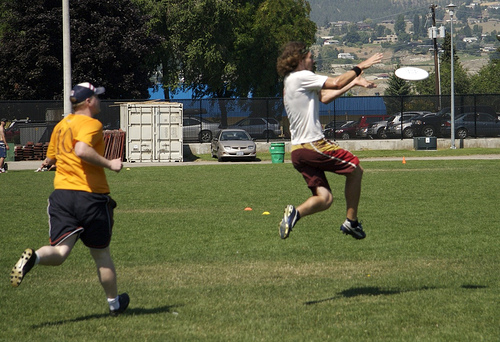

In [13]:
img

In [35]:
print(question)

Is there a frisbee in the image?


### Predict

In [16]:
inputs = model_wrapper.get_inputs(img, text)
pred_results = model_wrapper.predict(inputs, return_logits=True)

[transformers] Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


In [17]:
print(pred_results["text"])

Yes


### Generate explanations

In [20]:
model_wrapper.model_config = {
    "model_config": model_config,
    "attn_implementation": None,
    "gpu_node": gpu_id,
    "output_attentions": False
}

Specify the explanations methods you want to try.   
Available XAI methods are:
- `attnlrp`
- `rollout`
- `gradxrollout`
- `inputxgradients`
- `integratedgradients`
- `gradcam`
- `llavacam`
- `tam`

In [21]:
from src.explainers.factory import get_explainer

exp = "tam"
explainer_path = f"../configs/explainers/{exp}.yaml"

explainer, explainer_name = get_explainer(
            explainer_path, model_wrapper, model_config
        )

In [ ]:
target_indices = None

text_attrs, img_attrs = explainer.attribute(
    img,
    text=text,
    target_indices=target_indices,
    pred_results=pred_results,
    keyword=keyword,
    oracle_mask_2d=oracle_mask_2d,
    mismatched_mask_2d=mismatched_mask_2d,

)

In [23]:
img_attrs.shape

torch.Size([2, 1, 448, 448])

In [24]:
text_attrs.shape

torch.Size([2, 277])

### Metrics

#### Plausibility

To be able to compute the plausibility, you need the masks of the object.
So you must use the `coco` dataset for that.

In [39]:
dataset_name = "coco"

if dataset_name in ['repope', 'repope_oracle']:
    dataset_config = {
    "name": dataset_name,
    "data_path": "../datasets/repope",
    "pope_json_path": "../datasets/repope/repope_annotations",
    "pope_type": "all",
    "coco_split": "val2014",
    "batch_size": 1,
    }

elif dataset_name == "coco":
    dataset_config = {
        "name": dataset_name,
        "data_path": "../datasets/coco",
        "batch_size": 1
    }
    
else:

    dataset_config = f"../configs/datasets/{dataset_name}.yaml"
    dataset_config = load_yaml(dataset_config)

dl = get_dataloader(dataset_config)

[*] Loading Dataset: coco
loading annotations into memory...
Done (t=0.48s)
creating index...
index created!
loading annotations into memory...
Done (t=0.09s)
creating index...
index created!


In [44]:
inputs = model_wrapper.get_inputs(img, text)
pred_results = model_wrapper.predict(inputs, return_logits=True)

[transformers] Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


In [45]:
from src.explainers.factory import get_explainer

exp = "tam"
explainer_path = f"../configs/explainers/{exp}.yaml"

explainer, explainer_name = get_explainer(
            explainer_path, model_wrapper, model_config
        )

In [ ]:
from src.metrics import PlausibilityMetric
from src.utils.plausibility_utils import OntologyMapper, ids_to_word_groups

# Setup Ontology Mapper for Plausibility (Assume dl.dataset has id2name)
category_dict = getattr(dl.dataset, "id2name", {})
mapper = OntologyMapper(coco_categories=category_dict, threshold=0.5)

plaus_metrics = PlausibilityMetric(
        ontology_mapper=mapper,
        category_dict=category_dict
    )

In [ ]:
tokens = pred_results["new_ids"].cpu().unsqueeze(0).tolist()


In [ ]:
words, tokens_id_groups = ids_to_word_groups(tokens, model_wrapper.processor)
words

In [49]:
valid_words, target_indices = plaus_metrics.get_valid_targets(
                        words, tokens_id_groups, masks
                    )

In [50]:
valid_words

[{'word': 'TV', 'cat_name': 'tv', 'local_indices': [0]},
 {'word': 'dining', 'cat_name': 'dining table', 'local_indices': [1]},
 {'word': 'table', 'cat_name': 'dining table', 'local_indices': [2]},
 {'word': 'chairs', 'cat_name': 'chair', 'local_indices': [3]},
 {'word': 'person', 'cat_name': 'person', 'local_indices': [4]}]

In [51]:
text_attrs, img_attrs = explainer.attribute(
                        img,
                        text=text,
                        target_indices=target_indices,
                        pred_results=pred_results,
                    )

In [ ]:
xai_result = {
        "inputs": inputs,
        "target_ids": pred_results["new_ids"].unsqueeze(0),
        "pixel_attribution": img_attrs, 
        "token_attribution": text_attrs,
        "valid_words": valid_words  # Crucial for Plausibility to map rows to words
    }



In [52]:
from src.metrics import PlausibilityMetric

plaus_metrics = PlausibilityMetric(ontology_mapper=mapper, category_dict=category_dict)

In [53]:
faith_sample = {"image": img, "text": text}

# 6. Compute Both Metrics Using the Exact Same Data!
# faith_scores = faith_metrics.compute(model_wrapper, faith_sample, xai_result)
plaus_scores = plaus_metrics.compute(model_wrapper, sample, xai_result)


In [54]:
plaus_scores

{'time_plausibility': 2.1908432245254517e-05,
 'plaus_obj_iou': 0.0,
 'plaus_point_game': 0.0,
 'plaus_energy_score': 0.0}

#### Faithfulness

Compute here the faithfulness metrics:

- Synergistic faithfulness scores $\mathcal{{F}}_{{syn}}$
- Image SRG faithfulness scores $\mu_{{I}}^{{srg}}$
- Text SRG faithfulness scores $\mu_{{I}}^{{srg}}$

In [25]:
# 4. Metric Hyperparameters
pert_steps = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
device = model_wrapper.device
tok = model_wrapper.processor.tokenizer
pad_token_id = tok.pad_token_id if tok.pad_token_id is not None else 0
special_token_ids = model_wrapper.special_token_ids
filter_keywords = True

faith_metrics = FaithfulnessMetric(
    perturbation_steps=pert_steps,
    pad_token_id=pad_token_id,
    special_token_ids=model_wrapper.special_token_ids,
    mask_value=0.0,
    filter_keywords=filter_keywords,
)

In [26]:
xai_result = {
    "inputs": inputs,
    "target_ids": pred_results["new_ids"].unsqueeze(0),
    "pixel_attribution": img_attrs[0:1],
    "token_attribution": text_attrs[0:1],
}

faith_sample ={"image": img, "text": sample["question"]}

scores = faith_metrics.compute(model_wrapper, faith_sample, xai_result, 
                               required_metrics=["auc", "curve"])

In [34]:
from IPython.display import display, Math

# Scores
score_syn = scores["syn_synergy_norm_auc"]
score_img = scores["img_norm_auc_ins"] - scores["img_norm_auc_del"]
score_tok = scores["tok_norm_auc_ins"] - scores["tok_norm_auc_del"]

# Rendu visuel propre en LaTeX (le symbole : a été déplacé dans le bloc mathématique pour l'alignement)
display(Math(rf"\text{{Synergistic faithfulness scores }} (\mathcal{{F}}_{{syn}}) : {score_syn:.4f}"))
display(Math(rf"\text{{Image SRG faithfulness scores }} (\mu_{{I}}^{{srg}}) : {score_img:.4f}"))
display(Math(rf"\text{{Text SRG faithfulness scores }} (\mu_{{T}}^{{srg}}) : {score_tok:.4f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Visualization

You could visualize the inputs along their explanations.

In [28]:
from src.utils.viz_utils import XAIVisualizer
from src.utils.faithfulness_utils import get_text_mask

viz = XAIVisualizer(model_wrapper.processor)

In [29]:
token_attribution = text_attrs[0:1]
pixel_attribution = img_attrs[0:1]
target_ids = pred_results["new_ids"]

img_attrs = img_attrs.float()
text_attrs = text_attrs.float()

model_type = getattr(model_wrapper.model.config, "model_type", "").lower()
semantic_mask = get_text_mask(inputs["input_ids"],
                            model_type,
                            model_wrapper.processor.tokenizer)

In [30]:
viz.plot_text_attributions(
    text_attr=text_attrs, 
    input_ids=inputs["input_ids"], 
    target_ids=target_ids.unsqueeze(0),
    special_token_ids=model_wrapper.special_token_ids,
    semantic_mask=semantic_mask,
    target_indices=target_indices
)


TEXT ATTRIBUTIONS (Filtered & Normalized)


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
Yes,Yes (1.00),Yes,4.42,Is there a fr is bee in the image ?
<|im_end|>,<|im_end|> (1.00),<|im_end|>,3.63,Is there a fr is bee in the image ?



IMAGE ATTRIBUTIONS

[*] Heatmap for generated token: 'Yes'


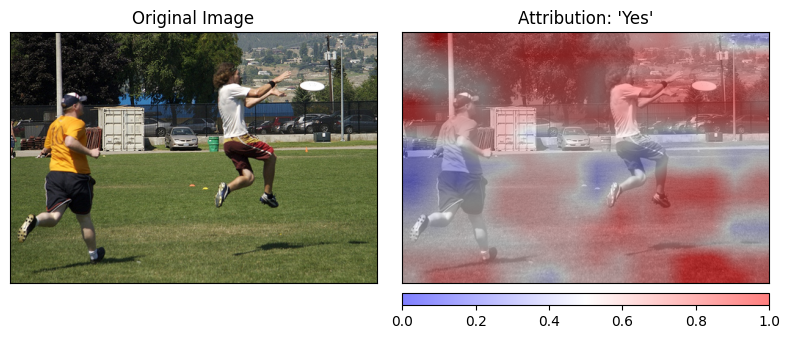

In [31]:
image_grid_thw = inputs.get("image_grid_thw", None)
viz.plot_image_attributions(img_attr=pixel_attribution,
                            original_image=img,
                            target_ids=target_ids.unsqueeze(0), 
                            image_grid_thw=image_grid_thw,
                            target_indices=target_indices
                            )